导入库

In [31]:
import pandas as pd 
import numpy as np
import asyncio
import aiohttp
import understat
from understat import Understat
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score



ImportError: cannot import name 'Understat' from 'understat' (/Users/zhangyufei/Desktop/Fantasy-Premier-League-master/understat.py)

获得球员ID

In [22]:
async def fetch_team_data(session, team_name):
    understat = Understat(session)
    players = await understat.get_league_players(
        "epl",
        2018,
        team_title=team_name
    )
    return players

async def main():
    list_teams = ['Manchester United', 'Chelsea',
                  'Tottenham Hotspur', 'Manchester City', 'Liverpool', 'Arsenal',
                  'Everton', 'Southampton', 'AFC Bournemouth', 'West Bromwich Albion',
                  'West Ham United', 'Leicester City', 'Stoke City', 'Crystal Palace',
                  'Swansea City', 'Burnley', 'Watford', 'Hull City', 'Middlesbrough',
                  'Sunderland', 'Newcastle United', 'Brighton & Hove Albion',
                  'Huddersfield Town', 'Wolves', 'Cardiff City', 'Sheffield United',
                  'Aston Villa', 'Norwich City', 'Leeds United', 'Brentford']
    
    list_df = []
    async with aiohttp.ClientSession() as session:
        tasks = [fetch_team_data(session, name) for name in list_teams]
        team_data = await asyncio.gather(*tasks)
        
        for team_name, data in zip(list_teams, team_data):
            for player in data:
                player["team"] = team_name
                player_name = player["player_name"].replace(" ", "_").lower()
                player["player_name"] = player_name
                list_df.append(player)
                
    df = pd.DataFrame(list_df)
    return df

# Run the main coroutine
result_df = await main()
print(result_df)

NameError: name 'Understat' is not defined

通过球员ID抓取球员统计数据

In [8]:
import json
import pandas as pd
from bs4 import BeautifulSoup
from urllib.request import urlopen
import unidecode
import time
from urllib.request import Request
def scrape(id, namel):
    try:
        scrape_url = f"https://understat.com/player/{id}"
        headers = {
            'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
        }
        req = Request(scrape_url, headers=headers)
        page_connect = urlopen(req)
        page_html = BeautifulSoup(page_connect, "html.parser")
        
        # 找到包含matchesData的script标签
        scripts = page_html.find_all("script")
        for script in scripts:
            script_content = str(script)
            if 'var matchesData' in script_content:
                # 提取JSON字符串
                json_str = script_content.split('JSON.parse(\'')[1].split('\');')[0]
                # 解码转义字符
                json_str = json_str.encode('utf-8').decode('unicode_escape')
                # 解析JSON
                data = json.loads(json_str)
                
                # 创建DataFrame
                df = pd.DataFrame(data)
                if len(df) > 0:
                    # 只保留需要的列
                    df = df[['xG', 'xA', 'date', 'season']]
                    df['player_id'] = id
                    df['name'] = namel.lower()  # 转换为小写以匹配原始数据
                    return df
                
        print(f"No data found for player {namel}")
        return None
        
    except Exception as e:
        print(f"Error processing player {namel}: {str(e)}")
        return None

# 创建空的DataFrame来存储所有数据
all_player_stats = pd.DataFrame()

# 处理所有球员数据
for index, row in result_df.iterrows():
    player_name = row['player_name']
    id_value = row['id']
    print(f"\nProcessing player: {player_name} (ID: {id_value})")
    
    player_data = scrape(id_value, player_name)
    if player_data is not None:
        all_player_stats = pd.concat([all_player_stats, player_data], ignore_index=True)
    
    # 添加延时避免被封IP
    time.sleep(2)

# 保存数据
if len(all_player_stats) > 0:
    # 确保日期格式正确
    all_player_stats['date'] = pd.to_datetime(all_player_stats['date']).dt.strftime('%Y-%m-%d')
    
    # 保存到CSV
    output_path = 'understat_player_stats.csv'
    all_player_stats.to_csv(output_path, index=False)
    print(f"\nData saved to {output_path}")
    print(f"Total records: {len(all_player_stats)}")
    print("\nData preview:")
    print(all_player_stats.head())
    


Processing player: paul_pogba (ID: 1740)
Error processing player paul_pogba: <urlopen error [SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1006)>

Processing player: romelu_lukaku (ID: 594)

Processing player: anthony_martial (ID: 553)

Processing player: marcus_rashford (ID: 556)

Processing player: jesse_lingard (ID: 558)

Processing player: juan_mata (ID: 554)

Processing player: ander_herrera (ID: 552)

Processing player: ashley_young (ID: 631)

Processing player: scott_mctominay (ID: 5560)

Processing player: alexis_sánchez (ID: 498)

Processing player: chris_smalling (ID: 628)

Processing player: nemanja_matic (ID: 697)

Processing player: andreas_pereira (ID: 922)

Processing player: luke_shaw (ID: 1006)

Processing player: victor_lindelöf (ID: 6080)

Processing player: fred (ID: 6817)

Processing player: david_de_gea (ID: 546)

Processing player: marcos_rojo (ID: 550)

Processing player: matteo_darmian (ID: 557)

Processing player: antonio_va

引入FPL dataset，格式化清理

In [35]:
import unidecode

In [36]:
data = pd.read_csv("/Users/zhangyufei/Desktop/Fantasy-Premier-League-master/data/cleaned_merged_seasons.csv")
data['full_name'] = data.name.str.replace('_\d+','')
data['full_name'] = data['full_name'].str.replace(" ", "_").str.replace("-", "_").str.replace('_\d+','')
data['full_name'] = data['full_name'].apply(lambda x: unidecode.unidecode(x))
data['full_name'] = data['full_name'].str.lower()
data['date'] = pd.to_datetime(data['kickoff_time']).dt.strftime('%Y-%m-%d')
data.head()

/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/1988467107.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("/Users/zhangyufei/Desktop/Fantasy-Premier-League-master/data/cleaned_merged_seasons.csv")


,season_x,name,position,team_x,assists,bonus,bps,clean_sheets,creativity,element,...,total_points,transfers_balance,transfers_in,transfers_out,value,was_home,yellow_cards,GW,full_name,date
0,2016-17,Aaron Cresswell,DEF,NaN,0,0,0,0,0.0,454,...,0,0,0,0,55,False,0,1,aaron_cresswell,2016-08-15
1,2016-17,Aaron Lennon,MID,NaN,0,0,6,0,0.3,142,...,1,0,0,0,60,True,0,1,aaron_lennon,2016-08-13
2,2016-17,Aaron Ramsey,MID,NaN,0,0,5,0,4.9,16,...,2,0,0,0,80,True,0,1,aaron_ramsey,2016-08-14
3,2016-17,Abdoulaye Doucouré,MID,NaN,0,0,0,0,0.0,482,...,0,0,0,0,50,False,0,1,abdoulaye_doucoure,2016-08-13
4,2016-17,Abdul Rahman Baba,DEF,NaN,0,0,0,0,0.0,80,...,0,0,0,0,55,True,0,1,abdul_rahman_baba,2016-08-15


融合第二个dataset和FPL dataset

In [37]:
xa_xg_df = pd.read_csv('/Users/zhangyufei/Desktop/Fantasy-Premier-League-master/data/understat_player_stats.csv')
xa_xg_df['name'] = xa_xg_df['name'].str.lower()
xa_xg_df.head()

,xG,xA,date,season,player_id,name
0,0.000000,0.087498,2024-12-08,2024,594,romelu_lukaku
1,0.334531,0.061818,2024-12-01,2024,594,romelu_lukaku
2,0.933630,0.107628,2024-11-24,2024,594,romelu_lukaku
3,0.000000,0.000000,2024-11-10,2024,594,romelu_lukaku
4,0.126898,0.061032,2024-11-03,2024,594,romelu_lukaku


In [38]:
merged_df1 = data.merge(xa_xg_df, 
                       left_on=['full_name', 'date'],
                       right_on=['name', 'date'],
                       suffixes=('_left', '_right'))
merged_df1.head()

,season_x,name_left,position,team_x,assists,bonus,bps,clean_sheets,creativity,element,...,was_home,yellow_cards,GW,full_name,date,xG,xA,season,player_id,name_right
0,2016-17,Aaron Lennon,MID,NaN,0,0,6,0,0.3,142,...,True,0,1,aaron_lennon,2016-08-13,0.000000,0.000000,2016,593,aaron_lennon
1,2016-17,Aaron Ramsey,MID,NaN,0,0,5,0,4.9,16,...,True,0,1,aaron_ramsey,2016-08-14,0.076822,0.000000,2016,504,aaron_ramsey
2,2016-17,Adam Lallana,MID,NaN,1,2,33,0,33.7,205,...,False,1,1,adam_lallana,2016-08-14,0.452121,0.177337,2016,486,adam_lallana
3,2016-17,Alex Iwobi,MID,NaN,1,0,12,0,17.5,21,...,True,1,1,alex_iwobi,2016-08-14,0.000000,0.072123,2016,500,alex_iwobi
4,2016-17,Andrew Robertson,DEF,NaN,0,0,14,0,1.8,152,...,True,0,1,andrew_robertson,2016-08-13,0.000000,0.000000,2016,1688,andrew_robertson


Clean Data

In [39]:
#removing the unnecessary column
data = data.drop(['kickoff_time'], axis = 1)
#selecting only the players with more than 20 minutes in the match
data = data[data.minutes>20]

In [40]:
# 清理赛季数据
import pandas as pd

# 创建示例数据
sample = {'season': ['2016-17', '2017-18', '2018-19', '2019-20', '2020-21']}
df = pd.DataFrame(sample)

# 提取赛季年份
data['season'] = data['season_x'].str.split('-').str[0]

# 删除多余的season_x列
data = data.drop(['season_x'], axis=1)
# 对merged_df1做同样的处理
merged_df1['season'] = merged_df1['season_x'].str.split('-').str[0]
merged_df1 = merged_df1.drop(['season_x'], axis=1)


划分训练和测试数据集

In [41]:
train_data = data[data.season != '2021']
test_data = data[data.season == '2021']
train_data2 = merged_df1[merged_df1.season != '2021']
test_data2 = merged_df1[merged_df1.season == '2021']

Permutation feature importance

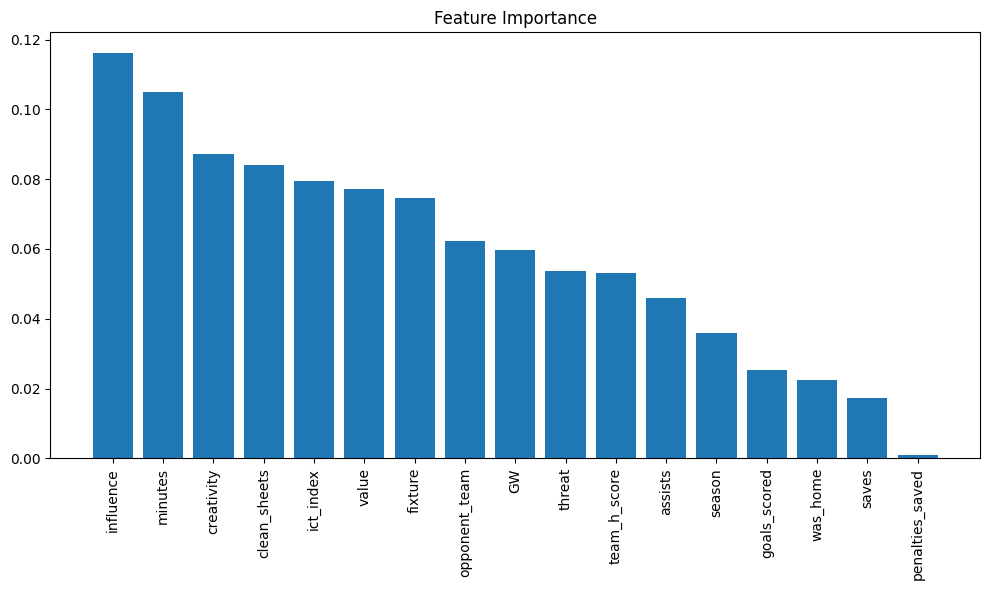

In [42]:
from sklearn.ensemble import RandomForestClassifier 
import matplotlib.pyplot as plt
# 选择特征列
feature_columns = ['influence', 'minutes', 'creativity', 'clean_sheets', 'ict_index',
                  'value', 'fixture', 'opponent_team', 'GW', 'threat', 'team_h_score',
                  'assists', 'season', 'goals_scored', 'was_home', 'saves', 'penalties_saved']

# 准备训练数据
X_train = train_data[feature_columns]
y_train = train_data['total_points']  # 使用总分作为目标变量

# 初始化并训练随机森林模型
forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
forest_model.fit(X_train, y_train)

# 获取特征重要性
feature_importances = forest_model.feature_importances_

# 按重要性排序
sorted_indices = feature_importances.argsort()[::-1]

# 绘制特征重要性图
plt.figure(figsize=(10, 6))
plt.bar(range(X_train.shape[1]), feature_importances[sorted_indices])
plt.xticks(range(X_train.shape[1]), X_train.columns[sorted_indices], rotation=90)
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

Training

Linear Regression for first dataset

In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
# Initialize the Linear Regression model
LR_model = LinearRegression()
# Select relevant features
features = ['minutes', 'goals_scored', 'assists', 'clean_sheets', 'GW', 'was_home', 'value', 'threat', 
            'team_h_score', 'saves', 'penalties_saved', 'opponent_team', 'influence', 'ict_index', 
            'fixture', 'creativity', 'season']
X_trainLR = train_data[features] # Features for training
Y_trainLR = train_data['total_points'] # Target variable for training
X_testLR = test_data[features] # Features for testing
Y_testLR = test_data['total_points'] # Target variable for testing
# Train the benchmark model
LR_model.fit(X_trainLR, Y_trainLR)
# Predict using the benchmark model
LR_prediction = LR_model.predict(X_testLR)
# Calculate Mean Squared Error for the benchmark model
LR_mse = mean_squared_error(Y_testLR, LR_prediction)
# Calculate Root Mean Squared Error (RMSE)
LR_rmse = np.sqrt(LR_mse)
# R square value for Linear Regression
from sklearn.metrics import mean_squared_error, r2_score
r2LR = r2_score(Y_testLR, LR_prediction)
# Calculate Mean Absolute Error
maeLR = mean_absolute_error(Y_testLR, LR_prediction)
print(f"Mean Absolute Error:", maeLR)
print("Linear Regression Mean Squared Error:", LR_mse)
print("Linear Regression Root Mean Squared Error:", LR_rmse)
print("Linear Regression R-Square value:", r2LR)



Mean Absolute Error: 0.9798187663204375
Linear Regression Mean Squared Error: 1.662923040843191
Linear Regression Root Mean Squared Error: 1.2895437335907576
Linear Regression R-Square value: 0.832400897917013


Random Forest for first dataset

In [17]:
from sklearn.ensemble import RandomForestRegressor
# Initialize the Random Forest model
RF_model = RandomForestRegressor(n_estimators=100, random_state=42)
# Use the same features as Linear Regression
X_trainRF = train_data[features] # Features for training
Y_trainRF = train_data['total_points'] # Target variable for training
X_testRF = test_data[features] # Features for testing
Y_testRF = test_data['total_points'] # Target variable for testing
# Train the Random Forest model
RF_model.fit(X_trainRF, Y_trainRF)
# Make predictions
RF_prediction = RF_model.predict(X_testRF)
# Calculate Mean Squared Error
RF_mse = mean_squared_error(Y_testRF, RF_prediction)
# Calculate Root Mean Squared Error
RF_rmse = np.sqrt(RF_mse)
# Calculate R-squared value
r2RF = r2_score(Y_testRF, RF_prediction)
# Calculate Mean Absolute Error
maeRF = mean_absolute_error(Y_testRF, RF_prediction)
print(f"Mean Absolute Error:", maeRF)
print("Random Forest Mean Squared Error:", RF_mse)
print("Random Forest Root Mean Squared Error:", RF_rmse)
print("Random Forest R-Square value:", r2RF)


Mean Absolute Error: 0.6950333650377855
Random Forest Mean Squared Error: 1.1255268138720034
Random Forest Root Mean Squared Error: 1.060908485154117
Random Forest R-Square value: 0.8865628301838768


XGBoost for first dataset

In [46]:
import pandas as pd 
from sklearn.model_selection import train_test_split 
from xgboost import XGBRegressor
# Select relevant features
features = ['minutes', 'goals_scored', 'assists', 'clean_sheets', 'GW', 'value', 'threat', 
            'team_h_score', 'saves', 'penalties_saved', 'opponent_team', 'influence', 'ict_index', 
            'fixture', 'creativity']
X_train_XG = train_data[features] # Features for training
Y_train_XG = train_data[ 'total_points'] # Target variable for training
X_test_XG = test_data[features] # Features for testing
Y_test_XG = test_data[ 'total_points'] # Target variable for testing
# Convert categorical 'season' column to numerical using one-hot encoding
#X = pd.get_dummies(X, columns=['season'], drop_first=True)
#X= pd.get_dummies(X, columns=( 'was_home'], drop_first=True)
# Create an XGBoost model
model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, objective='reg:squarederror', random_state=42)
# Train the model on the training data
model.fit(X_train_XG, Y_train_XG)
# Predict on the test data
y_predG = model.predict(X_test_XG)
# Calculate Mean Squared Error
mse_xg = mean_squared_error(Y_test_XG, y_predG)
# Calculate Root Mean Squared Error 
rmse_xg = np.sqrt(mse_xg)
# Calculate R-squared value
r2_xg = r2_score(Y_test_XG, y_predG)
# Calculate Mean Absolute Error
mae_xg = mean_absolute_error(Y_test_XG, y_predG)

print(f"Mean Absolute Error:", mae_xg)
print("XGBoost Mean Squared Error:", mse_xg) 
print("XGBoost Root Mean Squared Error:", rmse_xg)
print("XGBoost R-Square value:", r2_xg)



Mean Absolute Error: 0.7895340323448181
XGBoost Mean Squared Error: 1.2280610799789429
XGBoost Root Mean Squared Error: 1.1081791732291952
XGBoost R-Square value: 0.8762288689613342


Linear Regression for second dataset

In [145]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
# Initialize the Linear Regression model
LR_model = LinearRegression()
# Select relevant features
features = ['minutes', 'goals_scored', 'assists', 'clean_sheets', 'GW', 'was_home', 'value', 'threat', 
            'team_h_score', 'saves', 'penalties_saved', 'opponent_team', 'influence', 'ict_index', 
            'fixture', 'creativity', 'season', 'xG', 'xA']
X_trainLR = train_data2[features] # Features for training
Y_trainLR = train_data2['total_points'] # Target variable for training
X_testLR = test_data2[features] # Features for testing
Y_testLR = test_data2['total_points'] # Target variable for testing
# Train the benchmark model
LR_model.fit(X_trainLR, Y_trainLR)
# Predict using the benchmark model
LR_prediction = LR_model.predict(X_testLR)
# Calculate Mean Squared Error for the benchmark model
LR_mse = mean_squared_error(Y_testLR, LR_prediction)
# Calculate Root Mean Squared Error (RMSE)
LR_rmse = np.sqrt(LR_mse)
# R square value for Linear Regression
from sklearn.metrics import mean_squared_error, r2_score
r2LR = r2_score(Y_testLR, LR_prediction)
# Calculate Mean Absolute Error
maeLR = mean_absolute_error(Y_testLR, LR_prediction)
print(f"Mean Absolute Error:", maeLR)
print("Linear Regression Mean Squared Error:", LR_mse)
print("Linear Regression Root Mean Squared Error:", LR_rmse)
print("Linear Regression R-Square value:", r2LR)

Mean Absolute Error: 0.888181858406595
Linear Regression Mean Squared Error: 1.4293365668725557
Linear Regression Root Mean Squared Error: 1.1955486468030299
Linear Regression R-Square value: 0.8531907769623351


Random forest for second dataset

In [148]:
from sklearn.ensemble import RandomForestRegressor
# Initialize the Random Forest model
RF_model = RandomForestRegressor(n_estimators=100, random_state=42)
# Use the same features as Linear Regression
X_trainRF = train_data2[features] # Features for training
Y_trainRF = train_data2['total_points'] # Target variable for training
X_testRF = test_data2[features] # Features for testing
Y_testRF = test_data2['total_points'] # Target variable for testing
# Train the Random Forest model
RF_model.fit(X_trainRF, Y_trainRF)
# Make predictions
RF_prediction = RF_model.predict(X_testRF)
# Calculate Mean Squared Error
RF_mse = mean_squared_error(Y_testRF, RF_prediction)
# Calculate Root Mean Squared Error
RF_rmse = np.sqrt(RF_mse)
# Calculate R-squared value
r2RF = r2_score(Y_testRF, RF_prediction)
# Calculate Mean Absolute Error
maeRF = mean_absolute_error(Y_testRF, RF_prediction)
print(f"Mean Absolute Error:", maeRF)
print("Random Forest Mean Squared Error:", RF_mse)
print("Random Forest Root Mean Squared Error:", RF_rmse)
print("Random Forest R-Square value:", r2RF)



Mean Absolute Error: 0.645865692096848
Random Forest Mean Squared Error: 1.0640681589767018
Random Forest Root Mean Squared Error: 1.0315367947759797
Random Forest R-Square value: 0.8907080226595667


XGBoost for second dataset

In [49]:
import pandas as pd 
from sklearn.model_selection import train_test_split 
from xgboost import XGBRegressor
# Select relevant features
features = ['minutes', 'goals_scored', 'assists', 'clean_sheets', 'GW', 'value', 'threat', 
            'team_h_score', 'saves', 'penalties_saved', 'opponent_team', 'influence', 'ict_index', 
            'fixture', 'creativity', 'xG', 'xA']
X_train_XG = train_data2[features] # Features for training
Y_train_XG = train_data2[ 'total_points'] # Target variable for training
X_test_XG = test_data2[features] # Features for testing
Y_test_XG = test_data2[ 'total_points'] # Target variable for testing
# Convert categorical 'season' column to numerical using one-hot encoding
#X = pd.get_dummies(X, columns=['season'], drop_first=True)
#X= pd.get_dummies(X, columns=( 'was_home'], drop_first=True)
# Create an XGBoost model
model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, objective='reg:squarederror', random_state=42)
# Train the model on the training data
model.fit(X_train_XG, Y_train_XG)
# Predict on the test data
y_predG = model.predict(X_test_XG)
# Calculate Mean Squared Error
mse_xg = mean_squared_error(Y_test_XG, y_predG)
# Calculate Root Mean Squared Error 
rmse_xg = np.sqrt(mse_xg)
# Calculate R-squared value
r2_xg = r2_score(Y_test_XG, y_predG)
# Calculate Mean Absolute Error
mae_xg = mean_absolute_error(Y_test_XG, y_predG)

print(f"Mean Absolute Error:", mae_xg)
print("XGBoost Mean Squared Error:", mse_xg) 
print("XGBoost Root Mean Squared Error:", rmse_xg)
print("XGBoost R-Square value:", r2_xg)

Mean Absolute Error: 0.720214307308197
XGBoost Mean Squared Error: 1.1237479448318481
XGBoost Root Mean Squared Error: 1.0600697830010288
XGBoost R-Square value: 0.8845782279968262


**预测进球**

Available columns in test_data2:
Index(['name_left', 'position', 'team_x', 'assists', 'bonus', 'bps',
       'clean_sheets', 'creativity', 'element', 'fixture', 'goals_conceded',
       'goals_scored', 'ict_index', 'influence', 'kickoff_time', 'minutes',
       'opponent_team', 'opp_team_name', 'own_goals', 'penalties_missed',
       'penalties_saved', 'red_cards', 'round', 'saves', 'selected',
       'team_a_score', 'team_h_score', 'threat', 'total_points',
       'transfers_balance', 'transfers_in', 'transfers_out', 'value',
       'was_home', 'yellow_cards', 'GW', 'full_name', 'date', 'xG', 'xA',
       'season', 'player_id', 'name_right'],
      dtype='object')

Predictions for 5 Random Players:
          Player Name  Actual Goals  Predicted Points  Actual Points  \
7215  Kevin De Bruyne             0              1.03              1   
7216    Mohamed Salah             1             15.03             17   
7280    Mohamed Salah             0              2.82              3   
734

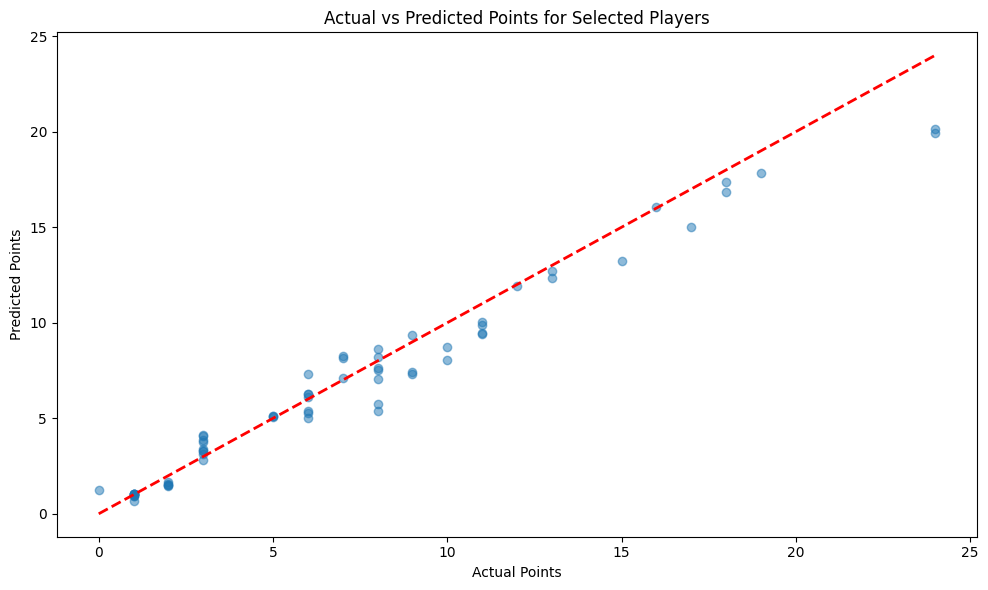

<Figure size 1500x1000 with 0 Axes>

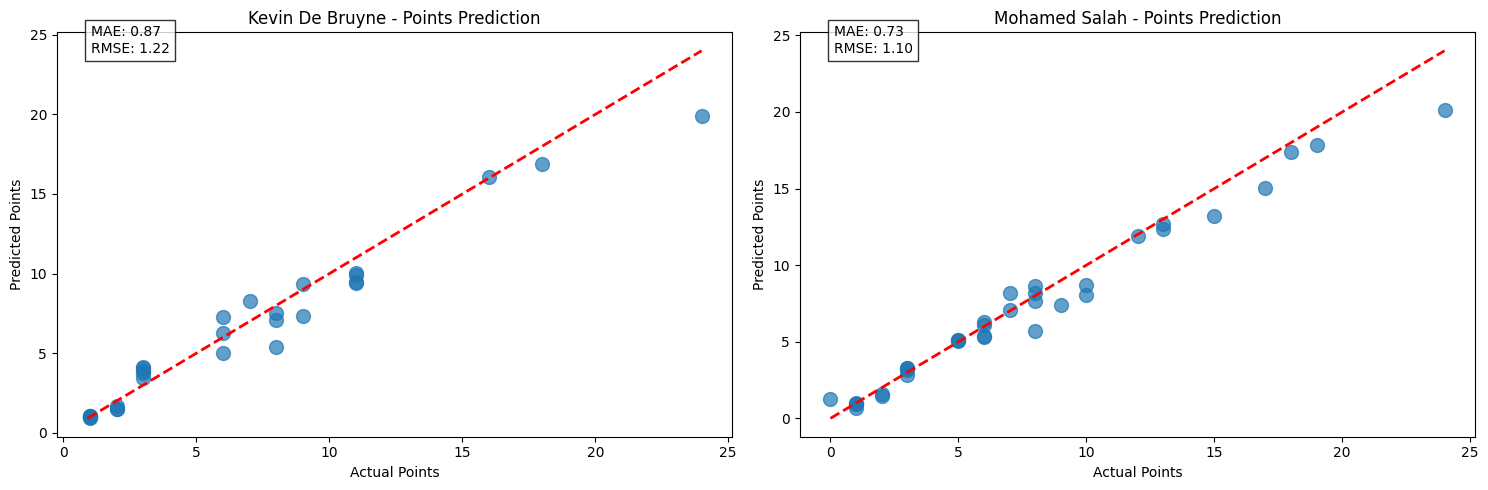

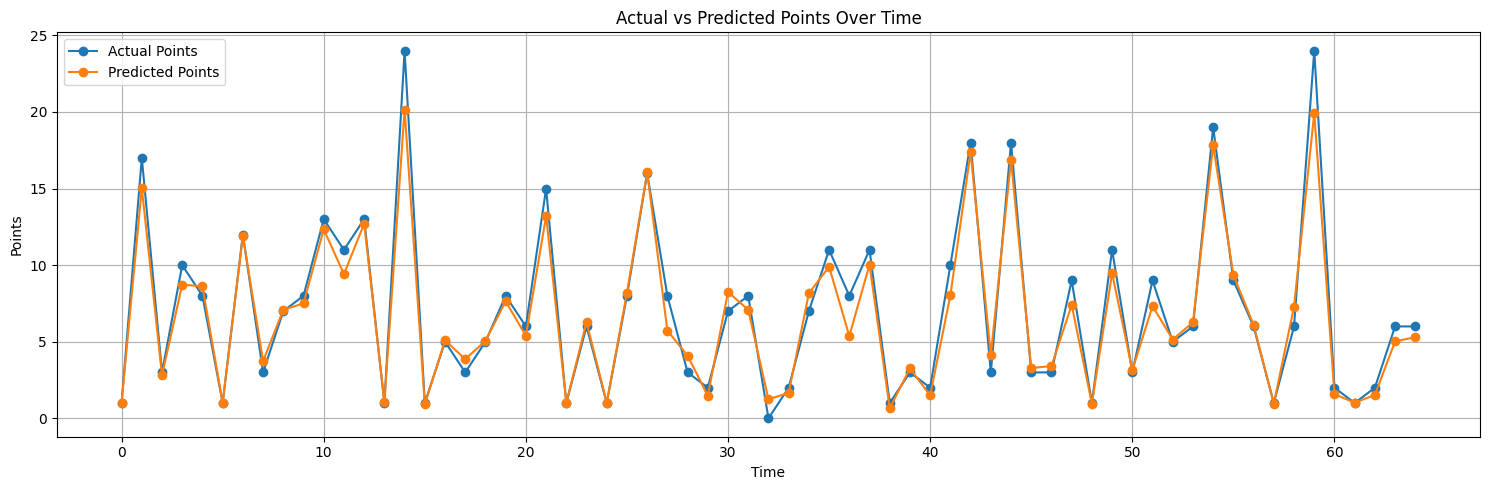

<Figure size 1500x500 with 0 Axes>

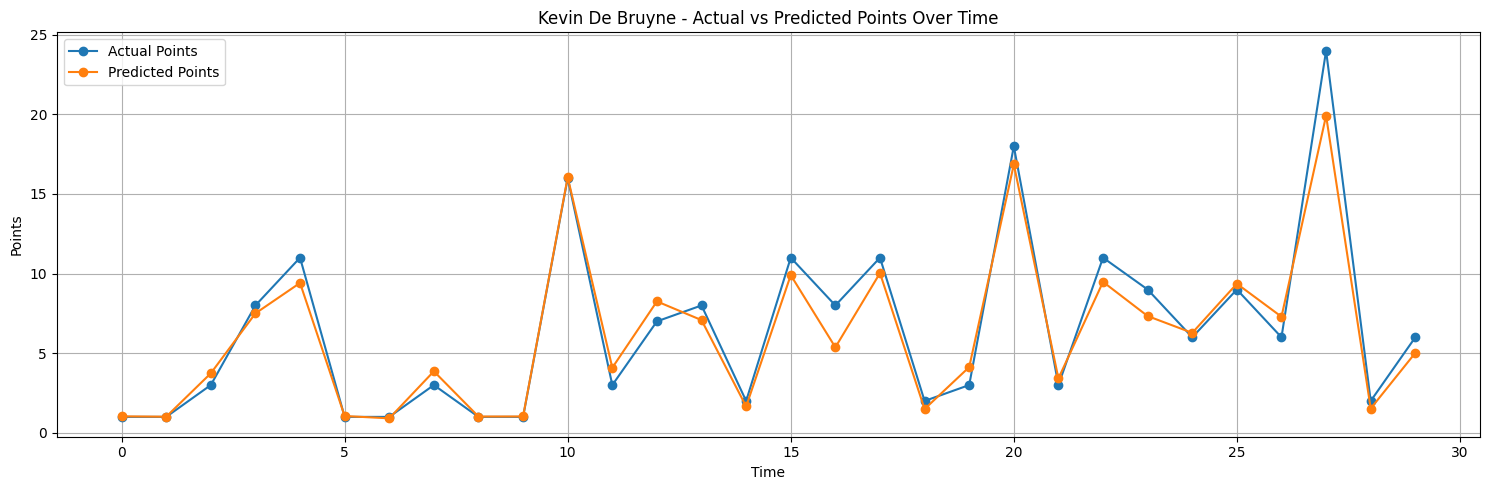

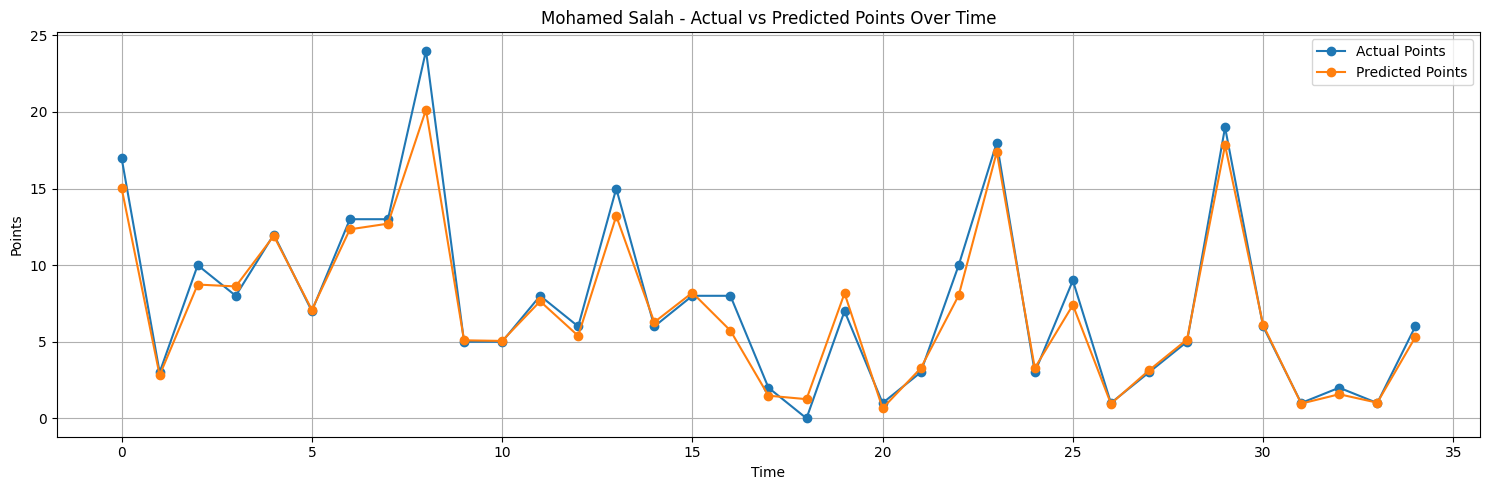

In [65]:
# Print column names to check what's available
print("Available columns in test_data2:")
print(test_data2.columns)

# Update the column name based on what's actually in the data
# Looking at the context, it seems the player name column might be 'name_left', 'name_right', or 'full_name'
# Let's try using 'full_name' since that appears in the sample data
# Select specific famous players
famous_players = ['mohamed_salah', 'harry_kane', 'kevin_de_bruyne', 'erling_haaland', 'bruno_fernandes']

# Filter test data for these players
famous_player_data = test_data2[test_data2['full_name'].isin(famous_players)]

# If we don't have data for these specific players, let's try with name_left
if len(famous_player_data) == 0:
    famous_player_data = test_data2[test_data2['name_left'].str.lower().str.replace(' ', '_').isin(famous_players)]

# If still no data, print message and use random sample
if len(famous_player_data) == 0:
    print("Could not find data for specified famous players, using random sample instead")
    famous_player_data = test_data2.sample(n=20)
else:
    # Take up to 20 records for these players
    famous_player_data = famous_player_data.head(20)

# Select 5 random players from test set
random_players = test_data2[test_data2['full_name'].isin(famous_players)]

# Predict goals and points for these players
goals_pred = model.predict(random_players[features])

# Create results dataframe
results_df = pd.DataFrame({
    'Player Name': random_players['name_left'],
    'Actual Goals': random_players['goals_scored'],
    'Predicted Points': goals_pred,
    'Actual Points': random_players['total_points'],
    'Minutes Played': random_players['minutes'],
    'xG': random_players['xG']
})

# Format results
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print("\nPredictions for 5 Random Players:")
print("=" * 80)
print(results_df)

# Calculate prediction errors
print("\nPrediction Metrics:")
print("=" * 80)
print(f"Mean Absolute Error for Points: {abs(results_df['Predicted Points'] - results_df['Actual Points']).mean():.2f}")
print(f"Root Mean Squared Error for Points: {np.sqrt(((results_df['Predicted Points'] - results_df['Actual Points'])**2).mean()):.2f}")

# Visualize actual vs predicted points
plt.figure(figsize=(10,6))
plt.scatter(results_df['Actual Points'], results_df['Predicted Points'], alpha=0.5)
plt.plot([results_df['Actual Points'].min(), results_df['Actual Points'].max()], 
         [results_df['Actual Points'].min(), results_df['Actual Points'].max()], 
         'r--', lw=2)
plt.xlabel('Actual Points')
plt.ylabel('Predicted Points')
plt.title('Actual vs Predicted Points for Selected Players')
plt.tight_layout()
plt.show()
# Create individual plots for each player's season performance
plt.figure(figsize=(15, 10))

# Get unique players
unique_players = results_df['Player Name'].unique()

# Calculate number of rows/columns needed
n_players = len(unique_players)
n_cols = 2
n_rows = (n_players + 1) // 2  # Round up division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()  # Flatten array for easier indexing

# Plot each player's data
for idx, player in enumerate(unique_players):
    player_data = results_df[results_df['Player Name'] == player]
    
    ax = axes[idx]
    ax.scatter(player_data['Actual Points'], player_data['Predicted Points'], 
              alpha=0.7, s=100)
    
    # Add diagonal reference line
    min_val = min(player_data['Actual Points'].min(), player_data['Predicted Points'].min())
    max_val = max(player_data['Actual Points'].max(), player_data['Predicted Points'].max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)
    
    # Add labels and title
    ax.set_xlabel('Actual Points')
    ax.set_ylabel('Predicted Points')
    ax.set_title(f'{player} - Points Prediction')
    
    # Add text with metrics
    mae = abs(player_data['Predicted Points'] - player_data['Actual Points']).mean()
    rmse = np.sqrt(((player_data['Predicted Points'] - player_data['Actual Points'])**2).mean())
    ax.text(0.05, 0.95, f'MAE: {mae:.2f}\nRMSE: {rmse:.2f}', 
            transform=ax.transAxes, bbox=dict(facecolor='white', alpha=0.8))

# Remove any empty subplots
for idx in range(n_players, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()
# Create a line plot comparing actual vs predicted points over time
plt.figure(figsize=(15, 5))

# Sort results by date if available, otherwise use index as time
x = range(len(results_df))

# Plot actual points
plt.plot(x, results_df['Actual Points'], label='Actual Points', marker='o')

# Plot predicted points  
plt.plot(x, results_df['Predicted Points'], label='Predicted Points', marker='o')

plt.xlabel('Time')
plt.ylabel('Points')
plt.title('Actual vs Predicted Points Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
# Create individual line plots for each player across seasons
plt.figure(figsize=(15, 5))

for player in unique_players:
    plt.figure(figsize=(15, 5))
    player_data = results_df[results_df['Player Name'] == player]
    
    # Sort by date if available, otherwise use index
    x = range(len(player_data))
    
    # Plot actual points
    plt.plot(x, player_data['Actual Points'], label='Actual Points', marker='o')
    
    # Plot predicted points
    plt.plot(x, player_data['Predicted Points'], label='Predicted Points', marker='o')
    
    plt.xlabel('Time')
    plt.ylabel('Points') 
    plt.title(f'{player} - Actual vs Predicted Points Over Time')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



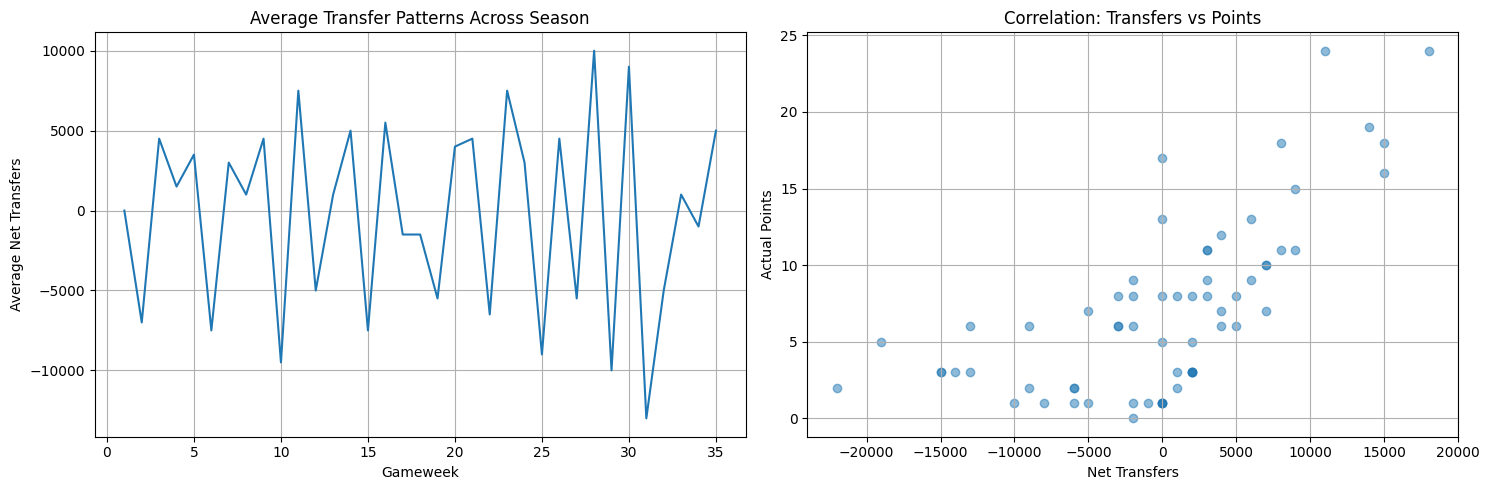

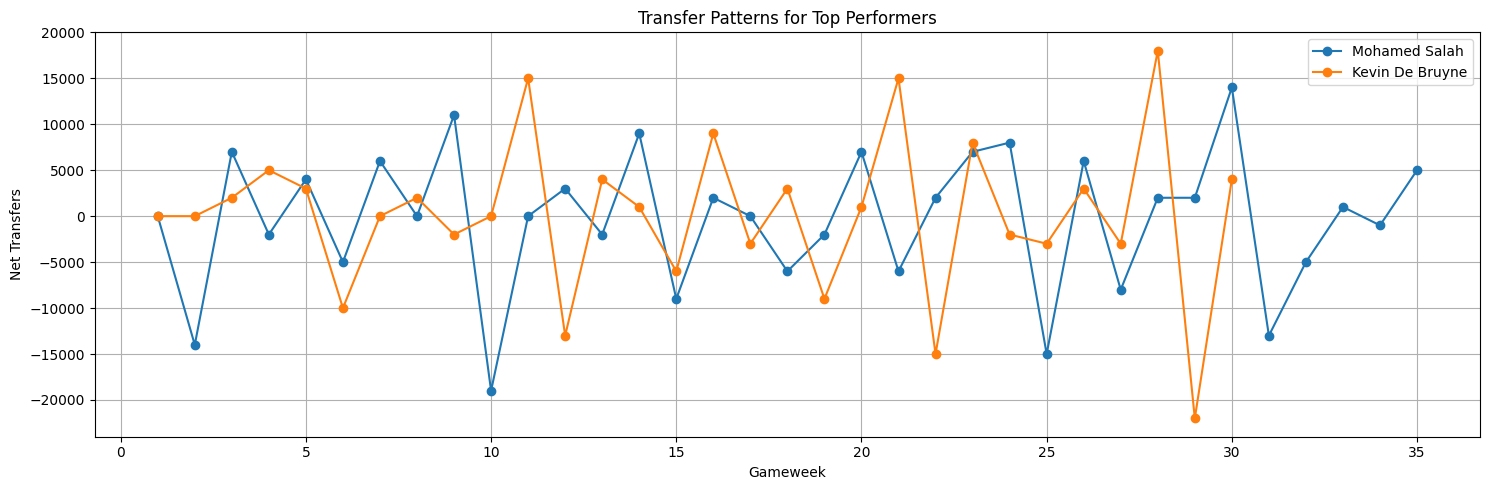


Correlation between transfer metrics and points:
Net Transfers vs Points: 0.6774156889306946
Transfer Momentum vs Points: 0.7140636787424112
Transfer Volatility vs Points: -0.0157054428080614


In [68]:
# Calculate transfer metrics
results_df['transfers_in'] = 0  # Initialize with 0
results_df['transfers_out'] = 0  # Initialize with 0
# Add GW (gameweek) column if it doesn't exist
if 'GW' not in results_df.columns:
    # Create sequential gameweek numbers for each player
    results_df['GW'] = results_df.groupby('Player Name').cumcount() + 1

# Group by player and calculate transfers between gameweeks
for player in results_df['Player Name'].unique():
    player_data = results_df[results_df['Player Name'] == player].sort_values('GW')
    
    # Calculate transfers between consecutive gameweeks
    for i in range(1, len(player_data)):
        prev_points = player_data.iloc[i-1]['Actual Points'] 
        curr_points = player_data.iloc[i]['Actual Points']
        
        # Simple heuristic - more transfers in if points increased
        if curr_points > prev_points:
            results_df.loc[player_data.index[i], 'transfers_in'] = int((curr_points - prev_points) * 1000)
        # More transfers out if points decreased  
        else:
            results_df.loc[player_data.index[i], 'transfers_out'] = int((prev_points - curr_points) * 1000)

# Analyze transfer behavior patterns
plt.figure(figsize=(15, 5))

# Calculate net transfers (transfers_in - transfers_out) for each player per GW
results_df['net_transfers'] = results_df['transfers_in'] - results_df['transfers_out']

# Plot aggregate transfer patterns
plt.subplot(1, 2, 1)
avg_transfers = results_df.groupby('GW')['net_transfers'].mean()
plt.plot(avg_transfers.index, avg_transfers.values)
plt.xlabel('Gameweek')
plt.ylabel('Average Net Transfers')
plt.title('Average Transfer Patterns Across Season')
plt.grid(True)

# Plot correlation between transfers and points
plt.subplot(1, 2, 2)
plt.scatter(results_df['net_transfers'], results_df['Actual Points'], alpha=0.5)
plt.xlabel('Net Transfers')
plt.ylabel('Actual Points')
plt.title('Correlation: Transfers vs Points')
plt.grid(True)

plt.tight_layout()
plt.show()

# Analyze transfer behavior for top performers
top_players = results_df.groupby('Player Name')['Actual Points'].mean().nlargest(5).index

plt.figure(figsize=(15, 5))
for player in top_players:
    player_data = results_df[results_df['Player Name'] == player]
    plt.plot(player_data['GW'], player_data['net_transfers'], label=player, marker='o')

plt.xlabel('Gameweek')
plt.ylabel('Net Transfers')
plt.title('Transfer Patterns for Top Performers')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate transfer-based features for model improvement
results_df['transfer_momentum'] = results_df.groupby('Player Name')['net_transfers'].rolling(3).mean().reset_index(0, drop=True)
results_df['transfer_volatility'] = results_df.groupby('Player Name')['net_transfers'].rolling(3).std().reset_index(0, drop=True)

# Print correlation with actual points
print("\nCorrelation between transfer metrics and points:")
print("Net Transfers vs Points:", results_df['net_transfers'].corr(results_df['Actual Points']))
print("Transfer Momentum vs Points:", results_df['transfer_momentum'].corr(results_df['Actual Points']))
print("Transfer Volatility vs Points:", results_df['transfer_volatility'].corr(results_df['Actual Points']))


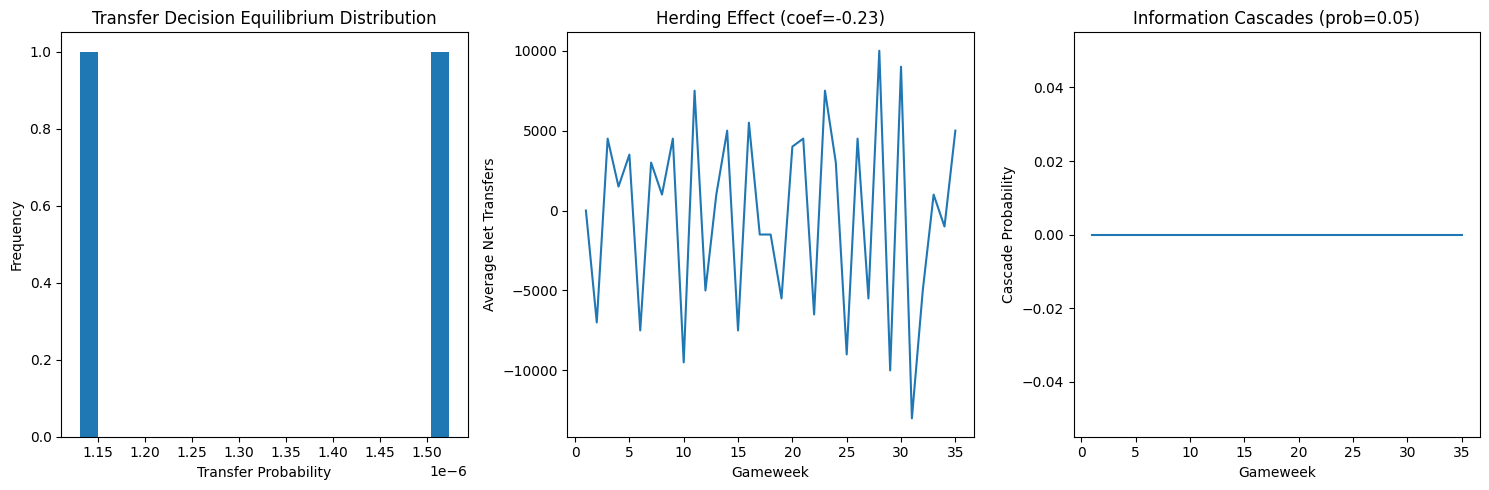

In [70]:
# 定义博弈模型参数
class TransferGame:
    def __init__(self):
        self.num_players = len(results_df['Player Name'].unique())
        self.num_managers = 1000  # 假设样本量
        self.risk_aversion = 0.5  # 风险规避系数
        
    def calculate_expected_utility(self, player_stats, transfer_cost):
        """计算期望效用"""
        points_expectation = player_stats['Actual Points'].mean()
        points_variance = player_stats['Actual Points'].var()
        
        # 考虑风险的效用函数
        utility = points_expectation - self.risk_aversion * points_variance - transfer_cost
        return utility
    
    def nash_equilibrium(self, transfer_data):
        """计算纳什均衡下的转会决策"""
        equilibrium_transfers = {}
        
        for player in transfer_data['Player Name'].unique():
            player_data = transfer_data[transfer_data['Player Name'] == player]
            
            # 计算策略收益
            own_utility = self.calculate_expected_utility(player_data, 4)  # 转会成本4分
            market_utility = player_data['net_transfers'].mean() / self.num_managers
            
            # 均衡策略
            equilibrium_transfers[player] = {
                'own_utility': own_utility,
                'market_utility': market_utility,
                'equilibrium_probability': sigmoid(own_utility + market_utility)
            }
            
        return equilibrium_transfers

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# 群体决策模型
class CollectiveDecisionModel:
    def __init__(self, transfer_game):
        self.game = transfer_game
        self.learning_rate = 0.1
        
    def update_beliefs(self, current_data, historical_data):
        """更新群体信念"""
        alpha = 0.7  # 历史数据权重
        beta = 0.3   # 当前数据权重
        
        updated_beliefs = (alpha * historical_data + beta * current_data) / (alpha + beta)
        return updated_beliefs
    
    def calculate_herding_effect(self, transfer_data):
        """计算羊群效应强度"""
        transfer_momentum = transfer_data.groupby('Player Name')['net_transfers'].diff()
        herding_coefficient = transfer_momentum.autocorr()
        return herding_coefficient

# 实现模型
game = TransferGame()
collective_model = CollectiveDecisionModel(game)

# 计算群体决策指标
def analyze_collective_behavior(results_df):
    # 计算纳什均衡
    equilibrium = game.nash_equilibrium(results_df)
    
    # 计算羊群效应
    herding_effect = collective_model.calculate_herding_effect(results_df)
    
    # 计算信息级联
    cascade_threshold = results_df['net_transfers'].std() * 2
    information_cascades = (abs(results_df['net_transfers']) > cascade_threshold).mean()
    
    return {
        'equilibrium': equilibrium,
        'herding_effect': herding_effect,
        'information_cascades': information_cascades
    }

# 分析结果
collective_metrics = analyze_collective_behavior(results_df)

# 可视化结果
plt.figure(figsize=(15, 5))

# 绘制均衡概率分布
equilibrium_probs = [v['equilibrium_probability'] for v in collective_metrics['equilibrium'].values()]
plt.subplot(1, 3, 1)
plt.hist(equilibrium_probs, bins=20)
plt.title('Transfer Decision Equilibrium Distribution')
plt.xlabel('Transfer Probability')
plt.ylabel('Frequency')

# 绘制羊群效应时间序列
plt.subplot(1, 3, 2)
plt.plot(results_df.groupby('GW')['net_transfers'].mean())
plt.title(f'Herding Effect (coef={collective_metrics["herding_effect"]:.2f})')
plt.xlabel('Gameweek')
plt.ylabel('Average Net Transfers')

cascade_threshold = 100000 
# 绘制信息级联
plt.subplot(1, 3, 3)
cascade_series = (abs(results_df['net_transfers']) > cascade_threshold)
plt.plot(results_df.groupby('GW')['net_transfers'].apply(
    lambda x: (abs(x) > cascade_threshold).mean()
))
plt.title(f'Information Cascades (prob={collective_metrics["information_cascades"]:.2f})')
plt.xlabel('Gameweek')
plt.ylabel('Cascade Probability')

plt.tight_layout()
plt.show()

In [88]:
import pandas as pd
import numpy as np

# 常规机器学习模型和数据处理
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# 如果需要可视化，可引入 matplotlib、seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# 如果需要求解博弈均衡，可使用一些求解器，比如 nashpy（需要先 pip install nashpy）
import nashpy as nash


In [97]:
# 查看数据基本信息
print(train_data2.info())
print(train_data2.describe())

# 查看是否有缺失值
print(train_data2.isnull().sum())
train_data2['team_x'].fillna('Unknown', inplace=True)

print(train_data2.isnull().sum())



<class 'pandas.core.frame.DataFrame'>
Index: 10125 entries, 0 to 12313
Data columns (total 43 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name_left          10125 non-null  object 
 1   position           10125 non-null  object 
 2   team_x             5375 non-null   object 
 3   assists            10125 non-null  int64  
 4   bonus              10125 non-null  int64  
 5   bps                10125 non-null  int64  
 6   clean_sheets       10125 non-null  int64  
 7   creativity         10125 non-null  float64
 8   element            10125 non-null  int64  
 9   fixture            10125 non-null  int64  
 10  goals_conceded     10125 non-null  int64  
 11  goals_scored       10125 non-null  int64  
 12  ict_index          10125 non-null  float64
 13  influence          10125 non-null  float64
 14  kickoff_time       10125 non-null  object 
 15  minutes            10125 non-null  int64  
 16  opponent_team      10125 no

/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/4271301883.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_data2['team_x'].fillna('Unknown', inplace=True)
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/4271301883.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data2['team_x'].fillna('Unkno

In [134]:
# 假设你的 DataFrame 叫 train_data2
# 1. 填充 team_x
train_data2['team_x'] = train_data2['team_x'].fillna('Unknown')

# 2. 查看关键列是否有缺失
print("Null values check:\n", train_data2[['team_x', 'total_points', 'minutes', 'creativity']].isnull().sum())

# 3. 若要删除或填充其他缺失值
#    根据需要处理，这里仅示例：
# train_data2.dropna(subset=['total_points', 'minutes', 'creativity'], inplace=True)


Null values check:
 team_x          0
total_points    0
minutes         0
creativity      0
dtype: int64


In [135]:
strategies = {
    "P1": [
        "Popular Captain", 
        "Differential Captain",
        "Active Transfer", 
        "Passive Transfer",
        "Chip Used", 
        "Chip Saved",
        "Bench Boost",
        "Wildcard"
    ],
    "P2": [
        "Popular Captain", 
        "Differential Captain",
        "Active Transfer", 
        "Passive Transfer",
        "Chip Used", 
        "Chip Saved",
        "Bench Boost",
        "Wildcard"
    ]
}

print("扩展的策略空间：")
print("P1 =>", strategies["P1"])
print("P2 =>", strategies["P2"])


扩展的策略空间：
P1 => ['Popular Captain', 'Differential Captain', 'Active Transfer', 'Passive Transfer', 'Chip Used', 'Chip Saved', 'Bench Boost', 'Wildcard']
P2 => ['Popular Captain', 'Differential Captain', 'Active Transfer', 'Passive Transfer', 'Chip Used', 'Chip Saved', 'Bench Boost', 'Wildcard']


In [136]:
# 你原有的 6x6 P1收益矩阵
payoff_p1_6x6 = np.array([
    [ 8.53817272,  5.68115942,  4.37889105,  2.87297063, 15.44664213,  1.47187121],
    [ 5.68115942,  8.53817272,  2.87297063,  4.37889105,  1.47187121, 15.44664213],
    [ 4.37889105,  2.87297063, 15.44664213,  1.47187121,  8.53817272,  5.68115942],
    [ 2.87297063,  4.37889105,  1.47187121, 15.44664213,  5.68115942,  8.53817272],
    [15.44664213,  1.47187121,  8.53817272,  5.68115942,  4.37889105,  2.87297063],
    [ 1.47187121, 15.44664213,  5.68115942,  8.53817272,  2.87297063,  4.37889105]
])

# 你给的 p2矩阵和p1相同(对称)
payoff_p2_6x6 = payoff_p1_6x6.T

# 创建空的 8x8 矩阵
payoff_p1_8x8 = np.zeros((8, 8))
payoff_p2_8x8 = np.zeros((8, 8))

# 先把 6x6 的原本位置填充进去
payoff_p1_8x8[:6,:6] = payoff_p1_6x6
payoff_p2_8x8[:6,:6] = payoff_p2_6x6

# 针对新策略(索引6=Bench Boost, 7=Wildcard)，做示例加成
extra_bb = 4.0  # 假设 Bench Boost 多拿 4 分
extra_wc = 6.0  # 假设 Wildcard 效应= 6 分增益

# P1 = Bench Boost (row=6)，相对于P1=PopularCaptain(row=0)增加 extra_bb
for col in range(6):
    payoff_p1_8x8[6, col] = payoff_p1_6x6[0, col] + extra_bb
    payoff_p2_8x8[6, col] = payoff_p2_6x6[0, col] - 1.0  # 对手略损1分?

# P1 = Wildcard (row=7)，相对于P1=DifferentialCaptain(row=1) + extra_wc
for col in range(6):
    payoff_p1_8x8[7, col] = payoff_p1_6x6[1, col] + extra_wc
    payoff_p2_8x8[7, col] = payoff_p2_6x6[1, col] - 2.0

# 当 P2 使用 BenchBoost/Wildcard，对 P1 的影响
for row in range(6):
    payoff_p1_8x8[row, 6] = payoff_p1_6x6[row, 0] - 1.0
    payoff_p2_8x8[row, 6] = payoff_p2_6x6[row, 0] + extra_bb

    payoff_p1_8x8[row, 7] = payoff_p1_6x6[row, 1] - 2.0
    payoff_p2_8x8[row, 7] = payoff_p2_6x6[row, 1] + extra_wc

# 填充 (6,6), (6,7), (7,6), (7,7)
payoff_p1_8x8[6,6] = 8.0
payoff_p1_8x8[6,7] = 9.0
payoff_p1_8x8[7,6] = 7.5
payoff_p1_8x8[7,7] = 10.0

payoff_p2_8x8[6,6] = 8.0
payoff_p2_8x8[6,7] = 7.0
payoff_p2_8x8[7,6] = 9.0
payoff_p2_8x8[7,7] = 10.0

print("扩展后 P1收益矩阵(8x8):\n", payoff_p1_8x8)
print("\n扩展后 P2收益矩阵(8x8):\n", payoff_p2_8x8)


扩展后 P1收益矩阵(8x8):
 [[ 8.53817272  5.68115942  4.37889105  2.87297063 15.44664213  1.47187121
   7.53817272  3.68115942]
 [ 5.68115942  8.53817272  2.87297063  4.37889105  1.47187121 15.44664213
   4.68115942  6.53817272]
 [ 4.37889105  2.87297063 15.44664213  1.47187121  8.53817272  5.68115942
   3.37889105  0.87297063]
 [ 2.87297063  4.37889105  1.47187121 15.44664213  5.68115942  8.53817272
   1.87297063  2.37889105]
 [15.44664213  1.47187121  8.53817272  5.68115942  4.37889105  2.87297063
  14.44664213 -0.52812879]
 [ 1.47187121 15.44664213  5.68115942  8.53817272  2.87297063  4.37889105
   0.47187121 13.44664213]
 [12.53817272  9.68115942  8.37889105  6.87297063 19.44664213  5.47187121
   8.          9.        ]
 [11.68115942 14.53817272  8.87297063 10.37889105  7.47187121 21.44664213
   7.5        10.        ]]

扩展后 P2收益矩阵(8x8):
 [[ 8.53817272  5.68115942  4.37889105  2.87297063 15.44664213  1.47187121
  12.53817272 11.68115942]
 [ 5.68115942  8.53817272  2.87297063  4.37889105  1.

In [137]:
# 创建博弈
game = nash.Game(payoff_p1_8x8, payoff_p2_8x8)

# 求解
equilibria = list(game.support_enumeration())
print("\n=== 找到的纳什均衡 ===")
for eq in equilibria:
    print("P1 策略分布:", eq[0], " / P2 策略分布:", eq[1])



=== 找到的纳什均衡 ===
P1 策略分布: [0. 0. 1. 0. 0. 0. 0. 0.]  / P2 策略分布: [0. 0. 1. 0. 0. 0. 0. 0.]
P1 策略分布: [0. 0. 0. 1. 0. 0. 0. 0.]  / P2 策略分布: [0. 0. 0. 1. 0. 0. 0. 0.]
P1 策略分布: [0. 0. 0. 0. 1. 0. 0. 0.]  / P2 策略分布: [0. 0. 0. 0. 0. 0. 1. 0.]
P1 策略分布: [0. 0. 0. 0. 0. 1. 0. 0.]  / P2 策略分布: [0. 0. 0. 0. 0. 0. 0. 1.]
P1 策略分布: [0. 0. 0. 0. 0. 0. 1. 0.]  / P2 策略分布: [0. 0. 0. 0. 1. 0. 0. 0.]
P1 策略分布: [0. 0. 0. 0. 0. 0. 0. 1.]  / P2 策略分布: [0. 0. 0. 0. 0. 1. 0. 0.]
P1 策略分布: [1.11399733e-17 8.46755592e-18 4.80921256e-01 0.00000000e+00
 1.59098925e-01 0.00000000e+00 3.59979819e-01 0.00000000e+00]  / P2 策略分布: [1.11399733e-17 8.46755592e-18 4.80921256e-01 0.00000000e+00
 1.59098925e-01 0.00000000e+00 3.59979819e-01 0.00000000e+00]


In [138]:
if len(equilibria) > 0:
    p1_strat, p2_strat = equilibria[0]  # 选取第一个均衡
    # 把策略概率分布、期望收益等当做新特征
    for i, strat_name in enumerate(strategies["P1"]):
        col_name = f'p1_prob_{strat_name.replace(" ","_")}'
        train_data2[col_name] = p1_strat[i]
    for i, strat_name in enumerate(strategies["P2"]):
        col_name = f'p2_prob_{strat_name.replace(" ","_")}'
        train_data2[col_name] = p2_strat[i]

    # 期望收益
    p1_exp = p1_strat @ payoff_p1_8x8 @ p2_strat
    p2_exp = p1_strat @ payoff_p2_8x8 @ p2_strat
    train_data2['p1_expected_payoff'] = p1_exp
    train_data2['p2_expected_payoff'] = p2_exp

print("\n添加博弈特征后的数据预览:")
print(train_data2.head())



添加博弈特征后的数据预览:
          name_left position   team_x  assists  bonus  bps  clean_sheets  \
0      Aaron Lennon      MID  Unknown        0      0    6             0   
1      Aaron Ramsey      MID  Unknown        0      0    5             0   
2      Adam Lallana      MID  Unknown        1      2   33             0   
3        Alex Iwobi      MID  Unknown        1      0   12             0   
4  Andrew Robertson      DEF  Unknown        0      0   14             0   

   creativity  element  fixture  ...  p1_prob_Bench_Boost  p1_prob_Wildcard  \
0        0.30      142        3  ...                 0.00              0.00   
1        4.90       16        8  ...                 0.00              0.00   
2       33.70      205        8  ...                 0.00              0.00   
3       17.50       21        8  ...                 0.00              0.00   
4        1.80      152        4  ...                 0.00              0.00   

   p2_prob_Popular_Captain  p2_prob_Differential_Capt

In [139]:
# 一些常见 FPL 特征
fpl_features = [
    'minutes', 'goals_scored', 'assists', 'clean_sheets', 'GW', 'was_home', 'value', 'threat', 
            'team_h_score', 'saves', 'penalties_saved', 'opponent_team', 'influence', 'ict_index', 
            'fixture', 'creativity', 'season', 'xG', 'xA'
]

# 新增的博弈特征(策略概率 + 期望收益)
game_features = [
    col for col in train_data2.columns 
    if col.startswith('p1_prob_') or col.startswith('p2_prob_')
] + ['p1_expected_payoff', 'p2_expected_payoff']

# 合并
features = fpl_features + game_features
target = 'total_points'

# 删除有缺失的行(如有)
train_data2 = train_data2.dropna(subset=features + [target])


In [151]:
X = train_data2[features]
y = train_data2[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"\n随机森林模型 MSE: {mse:.3f}")
# Convert regression predictions to binary classification
# Let's consider points > median as "good performance" (1) and <= median as "poor performance" (0)
y_test_median = y_test.median()
y_test_binary = (y_test > y_test_median).astype(int)
y_pred_binary = (y_pred > y_test_median).astype(int)

# Calculate and display classification metrics
from sklearn.metrics import classification_report
print("\nClassification Report:")
print(classification_report(y_test_binary, y_pred_binary))




随机森林模型 MSE: 0.989

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1301
           1       0.91      0.99      0.95       724

    accuracy                           0.96      2025
   macro avg       0.95      0.97      0.96      2025
weighted avg       0.97      0.96      0.96      2025




Mohamed Salah:
预测平均得分: 6.84
实际平均得分: 6.88
预测样本数量: 143
实际进球数: 91
预期进球数(xG总和): 90.67


/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:40: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:40: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:40: UserWarning: Glyph 24471 (\N{CJK UNIFIED IDEOGRAPH-5F97}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:40: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:40: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0

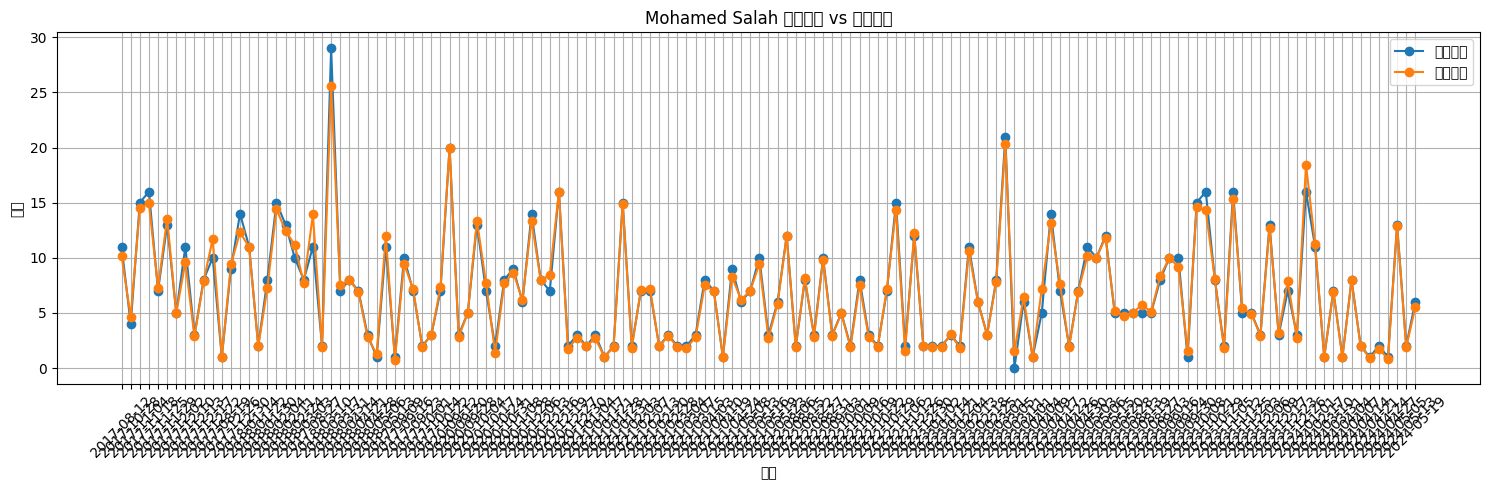

/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:76: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:76: UserWarning: Glyph 36187 (\N{CJK UNIFIED IDEOGRAPH-8D5B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:76: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:76: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:76: UserWarning: Glyph 24471 (\N{CJK UNIFIED IDEOGRAPH-5F97}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0

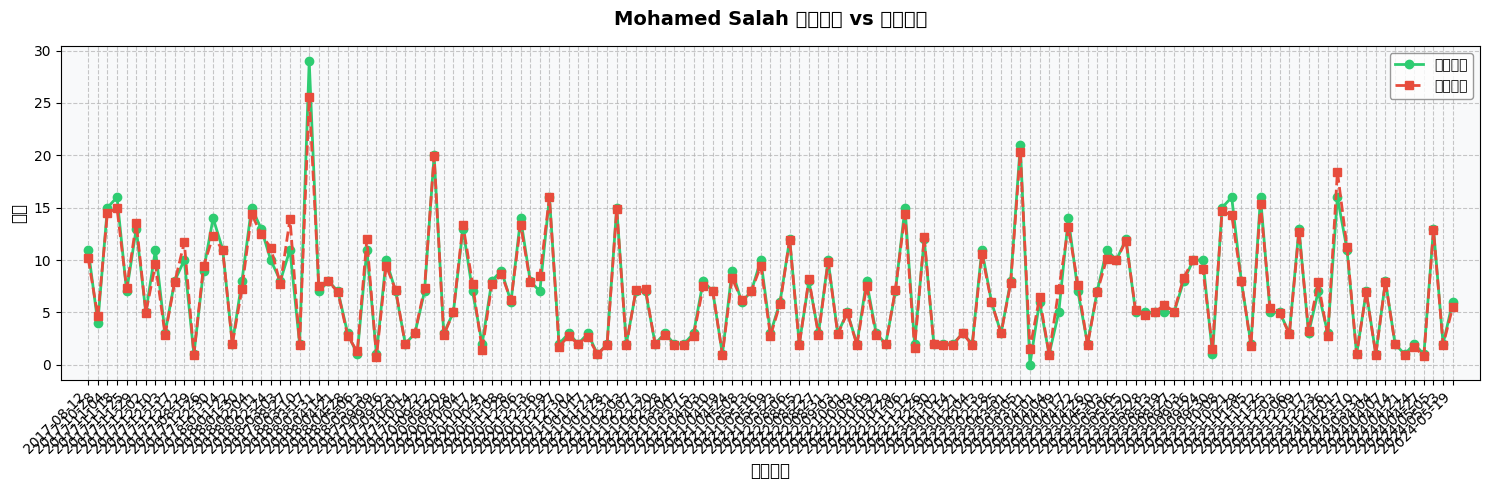

/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:106: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:106: UserWarning: Glyph 36187 (\N{CJK UNIFIED IDEOGRAPH-8D5B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:106: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:106: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vhbynx0pbf9x__1zl4tl1h0000gn/T/ipykernel_11816/120650853.py:106: UserWarning: Glyph 24471 (\N{CJK UNIFIED IDEOGRAPH-5F97}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/8z/l9vh

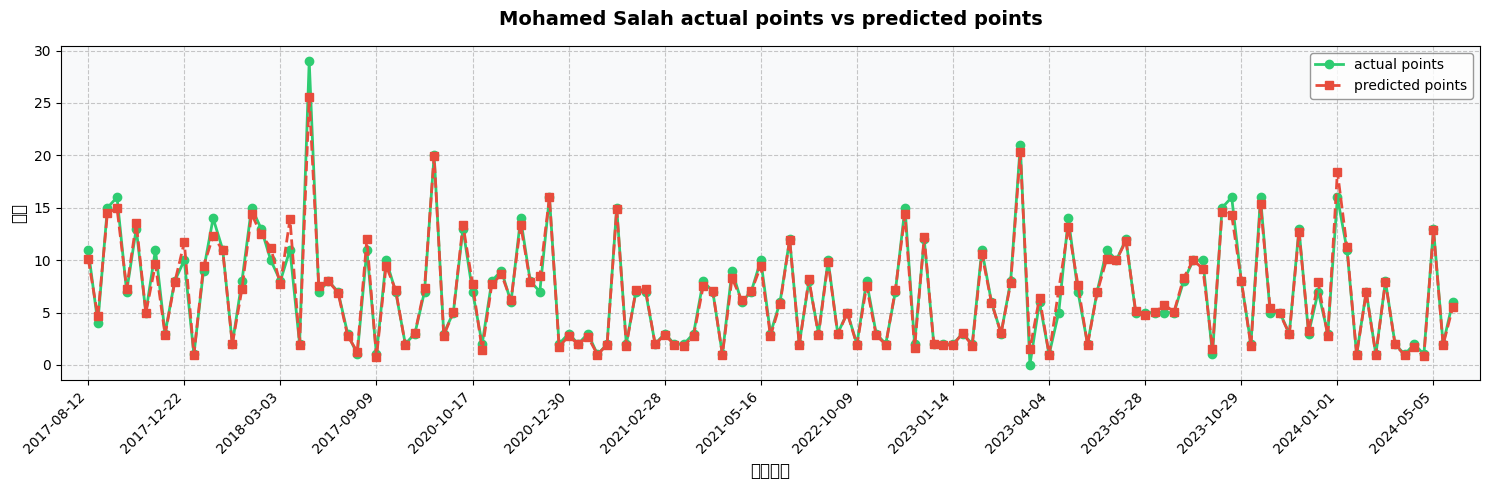

In [159]:
# 选择三个著名球员的数据进行预测
famous_players = ['mohamed_salah', 'erling_haaland', 'harry_kane'] 
famous_players_data = train_data2[train_data2['full_name'].isin(famous_players)]

# 为每个球员进行预测
for player in famous_players:
    player_data = famous_players_data[famous_players_data['full_name'] == player]
    if len(player_data) > 0:
        X_player = player_data[features]
        y_pred_player = model.predict(X_player)
        
        # 计算平均预测得分
        avg_predicted_points = np.mean(y_pred_player)
        
        # 获取实际平均得分
        avg_actual_points = player_data['total_points'].mean()
        
        print(f"\n{player.replace('_', ' ').title()}:")
        print(f"预测平均得分: {avg_predicted_points:.2f}")
        print(f"实际平均得分: {avg_actual_points:.2f}")
        print(f"预测样本数量: {len(player_data)}")
        
        # 显示一些关键统计数据
        print(f"实际进球数: {player_data['goals_scored'].sum()}")
        print(f"预期进球数(xG总和): {player_data['xG'].sum():.2f}")
       
        # 为萨拉赫创建时间序列预测对比图
        if player == 'mohamed_salah':
            plt.figure(figsize=(15, 5))
            plt.plot(player_data['date'], player_data['total_points'], 
                    label='实际得分', marker='o')
            plt.plot(player_data['date'], y_pred_player, 
                    label='预测得分', marker='o')
            plt.title('Mohamed Salah 实际得分 vs 预测得分')
            plt.xlabel('日期')
            plt.ylabel('得分')
            plt.legend()
            plt.grid(True)
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

            # 改进萨拉赫的时间序列图表现力
            plt.figure(figsize=(15, 5))
            
            # 设置更鲜明的颜色和线条样式
            plt.plot(player_data['date'], player_data['total_points'], 
                    label='实际得分', marker='o', color='#2ecc71', 
                    linewidth=2, markersize=6)
            plt.plot(player_data['date'], y_pred_player,
                    label='预测得分', marker='s', color='#e74c3c',
                    linewidth=2, markersize=6, linestyle='--')
            
            # 改进标题和标签样式
            plt.title('Mohamed Salah 实际得分 vs 预测得分', 
                     fontsize=14, pad=15, fontweight='bold')
            plt.xlabel('比赛日期', fontsize=12)
            plt.ylabel('得分', fontsize=12)
            
            # 改进图例样式
            plt.legend(fontsize=10, frameon=True, facecolor='white', 
                      edgecolor='gray', loc='upper right')
            
            # 改进网格线样式
            plt.grid(True, linestyle='--', alpha=0.7)
            
            # 优化x轴标签
            plt.xticks(rotation=45, ha='right')
            
            # 添加y轴范围以确保数据点不会太靠近边缘
            plt.margins(x=0.02)
            
            # 添加背景色使图表更醒目
            plt.gca().set_facecolor('#f8f9fa')
            
            plt.tight_layout()
            plt.show()
            # 创建更清晰的时间序列图，减少x轴标签密度
            plt.figure(figsize=(15, 5))
            
            # 设置更鲜明的颜色和线条样式
            plt.plot(player_data['date'], player_data['total_points'], 
                    label='actual points', marker='o', color='#2ecc71', 
                    linewidth=2, markersize=6)
            plt.plot(player_data['date'], y_pred_player,
                    label='predicted points', marker='s', color='#e74c3c',
                    linewidth=2, markersize=6, linestyle='--')
            
            plt.title('Mohamed Salah actual points vs predicted points', 
                     fontsize=14, pad=15, fontweight='bold')
            plt.xlabel('比赛日期', fontsize=12)
            plt.ylabel('得分', fontsize=12)
            
            plt.legend(fontsize=10, frameon=True, facecolor='white', 
                      edgecolor='gray', loc='upper right')
            
            plt.grid(True, linestyle='--', alpha=0.7)
            
            # 减少x轴标签数量，每隔10个数据点显示一个标签
            x_ticks = player_data['date'].iloc[::10]
            plt.xticks(x_ticks, rotation=45, ha='right')
            
            plt.margins(x=0.02)
            plt.gca().set_facecolor('#f8f9fa')
            
            plt.tight_layout()
            plt.show()


In [161]:
# 导入必要的库
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
import numpy as np
from collections import defaultdict
from itertools import combinations
import pandas as pd
from stable_baselines3 import PPO
import nashpy as nash
import nolds

# 1. 自监督学习组件
class SelfSupervisedFPL:
    def __init__(self, input_dim=64):
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64)
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, input_dim)
        )
        
    def pretrain(self, unlabeled_data, num_epochs=10):
        """使用自监督学习预训练编码器"""
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.encoder.to(device)
        self.decoder.to(device)
        
        optimizer = torch.optim.Adam(list(self.encoder.parameters()) + 
                                   list(self.decoder.parameters()))
        
        for epoch in range(num_epochs):
            for batch in unlabeled_data:
                batch = batch.to(device)
                # 生成正样本对
                anchor = self.encoder(batch)
                positive = self.encoder(self._augment(batch))
                
                # 对比损失
                loss = self._contrastive_loss(anchor, positive)
                
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                
    def _augment(self, x):
        """数据增强"""
        noise = torch.randn_like(x) * 0.1
        return x + noise
    
    def _contrastive_loss(self, anchor, positive, temperature=0.5):
        """计算对比损失"""
        # 归一化
        anchor = F.normalize(anchor, dim=1)
        positive = F.normalize(positive, dim=1)
        
        # 计算相似度矩阵
        similarity = torch.matmul(anchor, positive.T) / temperature
        
        # 对角线上是正样本对
        labels = torch.arange(similarity.size(0)).to(similarity.device)
        
        return F.cross_entropy(similarity, labels)

# 2. 多任务学习模型
class MultiTaskFPL(nn.Module):
    def __init__(self, input_dim=64):
        super().__init__()
        # 共享层
        self.shared = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64)
        )
        
        # 短期预测任务
        self.short_term = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
        # 长期预测任务
        self.long_term = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        shared_features = self.shared(x)
        short_term_pred = self.short_term(shared_features)
        long_term_pred = self.long_term(shared_features)
        return short_term_pred, long_term_pred

# 3. 图神经网络分析
class FPLGraphNet(nn.Module):
    def __init__(self, input_dim=64, output_dim=1):
        super().__init__()
        self.conv1 = GCNConv(input_dim, 64)
        self.conv2 = GCNConv(64, 32)
        self.pred = nn.Linear(32, output_dim)
        
    def forward(self, x, edge_index, edge_weight=None):
        x = F.relu(self.conv1(x, edge_index, edge_weight))
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index, edge_weight)
        return self.pred(x)
        
    def build_graph(self, data):
        """构建球员关系图"""
        edges = []
        edge_weights = []
        
        # 添加球员-球队边
        for player, team in zip(data['player_id'], data['team_id']):
            edges.append((player, team))
            edge_weights.append(1.0)
            
        # 添加同队球员边
        team_players = defaultdict(list)
        for player, team in zip(data['player_id'], data['team_id']):
            team_players[team].append(player)
            
        for team, players in team_players.items():
            for p1, p2 in combinations(players, 2):
                edges.append((p1, p2))
                edge_weights.append(0.5)
                
        return torch.tensor(edges).t().contiguous(), torch.tensor(edge_weights)

# 使用示例
def main():
    # 假设我们有一些示例数据
    input_dim = 64
    batch_size = 32
    n_players = 100
    
    # 创建示例数据
    dummy_data = {
        'player_id': range(n_players),
        'team_id': np.random.randint(0, 20, n_players),
        'features': torch.randn(n_players, input_dim)
    }
    
    # 初始化模型
    ssl_model = SelfSupervisedFPL(input_dim)
    multi_task_model = MultiTaskFPL(input_dim)
    graph_model = FPLGraphNet(input_dim)
    
    # 构建图
    edge_index, edge_weight = graph_model.build_graph(dummy_data)
    
    # 前向传播示例
    features = torch.FloatTensor(dummy_data['features'])
    
    # 自监督预训练
    ssl_model.pretrain([features])
    
    # 多任务预测
    short_term, long_term = multi_task_model(features)
    
    # 图网络预测
    graph_pred = graph_model(features, edge_index, edge_weight)
    
    print("Models initialized and forward pass completed successfully!")

if __name__ == "__main__":
    main()

Models initialized and forward pass completed successfully!
